# 01 — Data preparation (AlProtein tomato case study)

What this notebook does:
1. Loads the **raw** sensor files (one per device) and turns them into one clean long table.
2. Loads the plant measurements and marks which days were **actually measured** vs **interpolated**.
3. Builds an index of all images (camera, capture time) and the plant → camera / plant → sensor-zone maps.
4. Saves clean files to `OUT_DIR` so the modelling notebooks start from them.

Only edit the `DATA_DIR` line in the next cell.

In [1]:
# --- Setup: mount Drive (Colab) and set paths -------------------------------
import os, re, glob
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# EDIT THIS: the folder that contains "2025" (i.e. the "25 tomato dataset" folder you uploaded)
DATA_DIR = Path('/content/drive/MyDrive/25 tomato dataset') if IN_COLAB else Path(os.environ.get('DATA_DIR', 'data'))
MONTH_DIR = DATA_DIR / '2025' / '202506'
OUT_DIR = DATA_DIR.parent / 'alprotein_outputs'   # clean tables go here (outside the raw data folder)
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert MONTH_DIR.exists(), f'Not found: {MONTH_DIR} — fix DATA_DIR'
for p in sorted(MONTH_DIR.rglob('*')):
    if p.is_dir():
        print(p.relative_to(MONTH_DIR), '—', len(list(p.glob('*.*'))), 'files')

Mounted at /content/drive
images — 0 files
images/11,411 — 150 files
images/111,211 — 145 files
images/214,311 — 150 files
images/511,611 — 150 files
images/514,614 — 150 files
processed_data — 0 files
processed_data/growth_index(after interpolation) — 13 files
processed_data/growth_index(final) — 13 files
processed_data/sensor_data — 1 files
raw_data — 0 files
raw_data/growth_index — 2 files
raw_data/sensor_data — 3 files


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
SEED = 42
np.random.seed(SEED)
LOCAL_TZ_OFFSET_H = 8   # greenhouse is in China (UTC+8); image names are unix timestamps (UTC)

## 1. Sensors

`processed_data/sensor_data.xlsx` is just the three raw device files pasted side by side, and on 1–10 June
the middle device has extra rows **without timestamps**. The raw files (`raw_data/sensor_data/sensor1-3.xlsx`)
each keep their own `时间` (time) column, so we load those instead.

Column names are Chinese: `<variable>（<zone>）<position>`, e.g. `空气温度（处理1）前` = air temperature, treatment 1, front.

In [3]:
VAR_MAP = {'二氧化碳': 'co2', '电压': 'voltage', '相对湿度': 'rh', '土壤水分': 'soil_moisture',
           '光照': 'light', '土壤温度': 'soil_temp', '空气温度': 'air_temp'}
POS_MAP = {'前': 'front', '中': 'middle', '后': 'back', '': ''}

def parse_col(col):
    """'空气温度（处理1）前' -> ('air_temp', 'T1', 'front');  '电压' -> ('voltage', None, '')"""
    col = col.strip()
    m = re.match(r'^(.+?)[（(](.+?)[）)]\s*(.*)$', col)
    if not m:
        return VAR_MAP.get(col, col), None, ''
    var, zone, pos = m.groups()
    zone = zone.replace('处理', 'T').replace('对照', 'CK')
    return VAR_MAP.get(var, var), zone, POS_MAP.get(pos.strip(), pos.strip())

frames = []
for f in sorted((MONTH_DIR / 'raw_data' / 'sensor_data').glob('sensor*.xlsx')):
    device = f.stem
    sheets = pd.read_excel(f, sheet_name=None)
    for sheet, df in sheets.items():
        df = df.rename(columns={df.columns[0]: 'time'})
        df['time'] = pd.to_datetime(df['time'], errors='coerce')
        long = df.melt(id_vars='time', var_name='raw_col', value_name='value')
        long['device'] = device
        frames.append(long)

sensors = pd.concat(frames, ignore_index=True)
parsed = sensors['raw_col'].map(parse_col)
sensors[['variable', 'zone', 'position']] = pd.DataFrame(parsed.tolist(), index=sensors.index)

# English name for each original column (the Chinese raw_col is kept for traceability)
sensors['raw_col_en'] = (sensors['variable'] + '_' + sensors['zone'].fillna('device')
                         + sensors['position'].map(lambda p: f'_{p}' if p else ''))

n0 = len(sensors)
sensors = sensors.dropna(subset=['time', 'value'])
n1 = len(sensors)
sensors = sensors.drop_duplicates(subset=['device', 'time', 'raw_col'])
n2 = len(sensors)
print(f'rows: {n0:,} raw -> {n1:,} after dropping empty -> {n2:,} after dropping duplicate timestamps')

(sensors[['device', 'raw_col_en', 'raw_col', 'variable', 'zone', 'position']]
 .drop_duplicates().sort_values(['device', 'variable']))

rows: 62,771 raw -> 62,771 after dropping empty -> 44,134 after dropping duplicate timestamps


,device,raw_col_en,raw_col,variable,zone,position
528,sensor1,air_temp_T1_front,空气温度（处理1）前,air_temp,T1,front
576,sensor1,air_temp_CK2_back,空气温度（对照2）后,air_temp,CK2,back
0,sensor1,co2_T1_front,二氧化碳（处理1）前,co2,T1,front
48,sensor1,co2_CK2_back,二氧化碳（对照2）后,co2,CK2,back
336,sensor1,light_T1_front,光照（处理1）前,light,T1,front
384,sensor1,light_CK2_back,光照（对照2）后,light,CK2,back
144,sensor1,rh_T1_front,相对湿度（处理1）前,rh,T1,front
192,sensor1,rh_CK2_back,相对湿度（对照2）后,rh,CK2,back
240,sensor1,soil_moisture_T1,土壤水分（处理1）,soil_moisture,T1,
288,sensor1,soil_moisture_CK2,土壤水分（对照2）,soil_moisture,CK2,


In [4]:
# Coverage: readings per device per day (a full day at 30-min = 48)
sensors['date'] = sensors['time'].dt.date
cov = (sensors[sensors.variable == 'air_temp']
       .groupby(['device', 'date'])['time'].nunique().unstack(0))
display(cov.T)
print('Expected 48 per day. sensor2 covers 1–10 June only; sensor1/3 start 2 June.')

date,2025-06-01,2025-06-02,2025-06-03,2025-06-04,2025-06-05,2025-06-06,2025-06-07,2025-06-08,2025-06-09,2025-06-10,2025-06-11,2025-06-12,2025-06-13,2025-06-14,2025-06-15,2025-06-16,2025-06-17,2025-06-18,2025-06-19,2025-06-20,2025-06-21,2025-06-22,2025-06-23,2025-06-24,2025-06-25,2025-06-26,2025-06-27,2025-06-28,2025-06-29,2025-06-30
device,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
sensor1,NaN,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0
sensor2,32.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sensor3,NaN,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0,48.0


Expected 48 per day. sensor2 covers 1–10 June only; sensor1/3 start 2 June.


In [5]:
# Summary stats + simple outlier check per variable
summary = sensors.groupby('variable')['value'].describe(percentiles=[.01, .5, .99])
display(summary)

# Values that are physically suspicious (tune the limits after looking at the table)
# Note: some devices write 0 when they drop out (0 °C / 0 % RH / 0 ppm CO2 in June is impossible) -> treat as missing
LIMITS = {'air_temp': (1, 50), 'soil_temp': (1, 45), 'rh': (1, 100),
          'co2': (150, 3000), 'soil_moisture': (0, 100), 'light': (0, None)}
def out_of_range(r):
    lo, hi = LIMITS.get(r.variable, (None, None))
    return (lo is not None and r.value < lo) or (hi is not None and r.value > hi)
sensors['flag_range'] = sensors.apply(out_of_range, axis=1)
print('Out-of-range readings:', sensors['flag_range'].sum())
display(sensors[sensors.flag_range].groupby(['device', 'raw_col']).size().rename('n'))

,count,mean,std,min,1%,50%,99%,max
variable,,,,,,,,
air_temp,6822.0,23.170896,5.629335,0.000000,12.379999,22.894998,34.877899,39.480000
co2,6822.0,490.182644,74.750632,0.000000,413.000000,477.000000,677.000000,786.000000
light,6822.0,4.828926,8.399613,0.000000,0.000000,1.030000,41.194300,59.720000
rh,6822.0,69.538548,16.281987,0.000000,29.125700,71.639999,91.740001,96.860001
soil_moisture,6822.0,45.888685,17.857849,18.700001,19.000000,42.200002,71.200005,72.500001
soil_temp,6822.0,22.106641,2.389214,15.200000,17.600000,22.000000,27.899999,29.600001
voltage,3202.0,11.863889,0.068623,11.670359,11.723185,11.857876,12.015496,12.059626


Out-of-range readings: 165


device   raw_col   
sensor1  二氧化碳（对照2）后     2
         相对湿度（对照2）后     2
         空气温度（对照2）后     2
sensor2  二氧化碳（处理5）     23
         二氧化碳（对照2）     29
         相对湿度（处理5）     23
         相对湿度（对照2）     29
         空气温度（处理5）     23
         空气温度（对照2）     29
sensor3  二氧化碳（处理1）后     1
         相对湿度（处理1）后     1
         空气温度（处理1）后     1
Name: n, dtype: int64

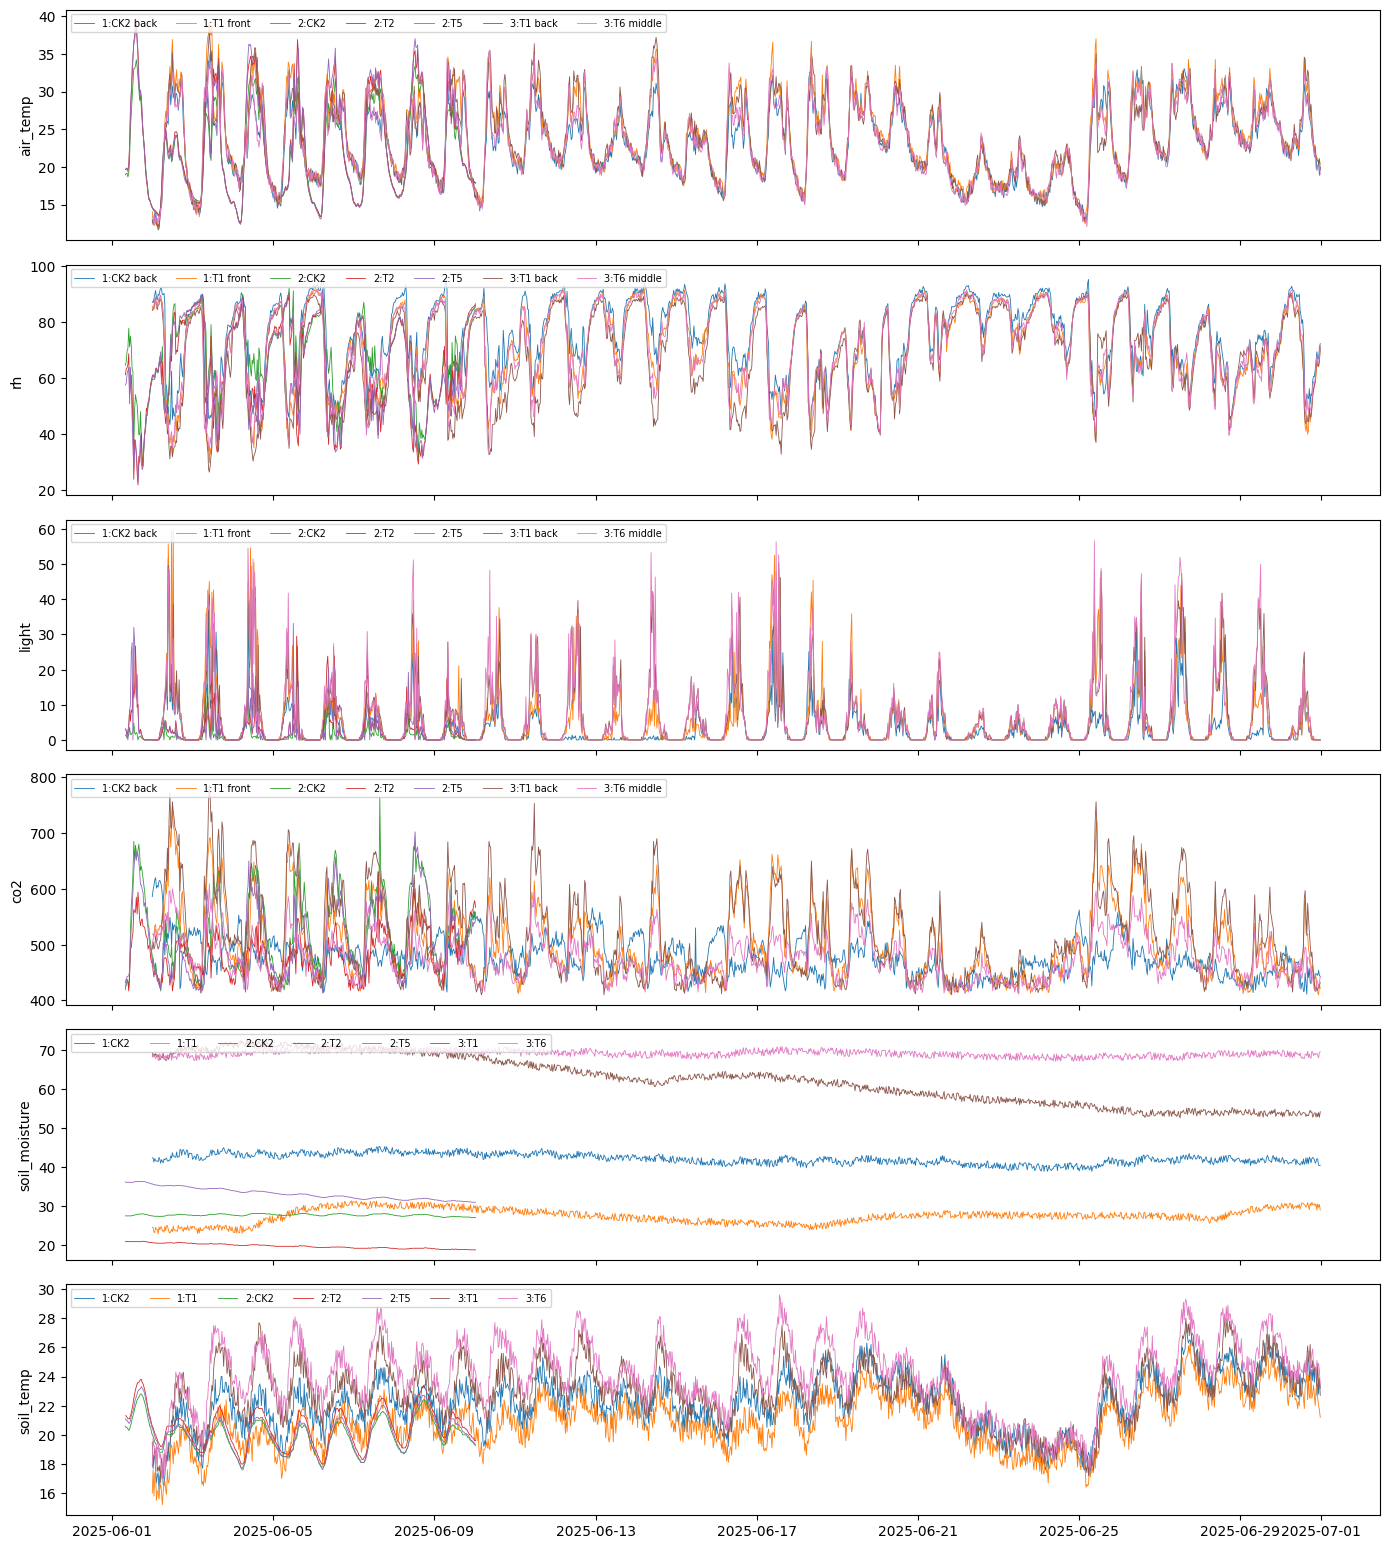

In [6]:
# Daily curves per probe (device + column), sorted by time
plot_vars = ['air_temp', 'rh', 'light', 'co2', 'soil_moisture', 'soil_temp']
fig, axes = plt.subplots(len(plot_vars), 1, figsize=(14, 2.6 * len(plot_vars)), sharex=True)
ok = sensors[~sensors.flag_range].sort_values('time')
for ax, v in zip(axes, plot_vars):
    for (dev, zone, pos), g in ok[ok.variable == v].groupby(['device', 'zone', 'position']):
        ax.plot(g['time'], g['value'], lw=.6, label=f'{dev[-1]}:{zone} {pos}'.strip())
    ax.set_ylabel(v)
    ax.legend(ncol=8, fontsize=7, loc='upper left')
plt.tight_layout(); plt.show()

**Things to write down from these plots (for the README / assumptions):**
- Which zones have sensors (T1, T2, T5, T6, CK2) and which treatments have **none** (T3, T4).
- Soil-moisture probes can sit at very different levels even in the same zone → probably placement/calibration, so compare *changes* rather than absolute levels across probes.
- Light units are not documented.
- Gaps: sensor2 (zones T2, T5, and one CK2 probe) stops after 10 June → from 11 June T2/T5 plants need the greenhouse mean as a fallback.
- Dropouts recorded as 0 (flagged above).

In [7]:
# Zone-level 30-min table
ok = sensors[~sensors.flag_range & sensors.zone.notna()].copy()
ok['time'] = ok['time'].dt.floor('30min')
ok['probe'] = ok['device'] + ':' + ok['raw_col']

# Soil probes sit at very different absolute levels (placement/calibration),
# so for soil we keep the change relative to each probe's own first-day mean.
SOIL = ['soil_moisture', 'soil_temp']
first_day = ok.groupby('probe')['time'].transform('min').dt.normalize()
base = (ok[ok['time'] < first_day + pd.Timedelta(days=1)]
        .groupby('probe')['value'].mean())
ok['value_delta'] = ok['value'] - ok['probe'].map(base)

air = (ok[~ok.variable.isin(SOIL)]
       .groupby(['zone', 'time', 'variable'])['value'].mean().unstack('variable'))
soil_delta = (ok[ok.variable.isin(SOIL)]
              .groupby(['zone', 'time', 'variable'])['value_delta'].mean().unstack('variable')
              .add_suffix('_delta'))
zone_ts = air.join(soil_delta, how='outer').reset_index()

# Greenhouse-wide average (fallback for T3/T4 and for T2/T5 after 10 June)
gh = zone_ts.drop(columns='zone').groupby('time').mean().reset_index().assign(zone='GH_MEAN')
zone_ts = pd.concat([zone_ts, gh], ignore_index=True).sort_values(['zone', 'time'])

zone_ts.to_parquet(OUT_DIR / 'sensors_zone_30min.parquet', index=False)
sensors.to_parquet(OUT_DIR / 'sensors_long.parquet', index=False)
print(zone_ts.columns.tolist())
zone_ts.groupby('zone')['time'].agg(['min', 'max', 'count'])

['zone', 'time', 'air_temp', 'co2', 'light', 'rh', 'soil_moisture_delta', 'soil_temp_delta']


,min,max,count
zone,,,
CK2,2025-06-01 08:00:00,2025-06-30 23:30:00,1424
GH_MEAN,2025-06-01 08:00:00,2025-06-30 23:30:00,1424
T1,2025-06-02 00:00:00,2025-06-30 23:30:00,1392
T2,2025-06-01 08:00:00,2025-06-10 00:30:00,418
T5,2025-06-01 08:00:00,2025-06-10 00:30:00,418
T6,2025-06-02 00:00:00,2025-06-30 23:30:00,1392


## 1b. Differences between days and greenhouse zones

Daily summaries per zone make day-to-day weather (e.g. cloudy days) and zone differences visible.
VPD (vapour-pressure deficit) combines temperature and humidity: high VPD = dry air = stronger transpiration demand.

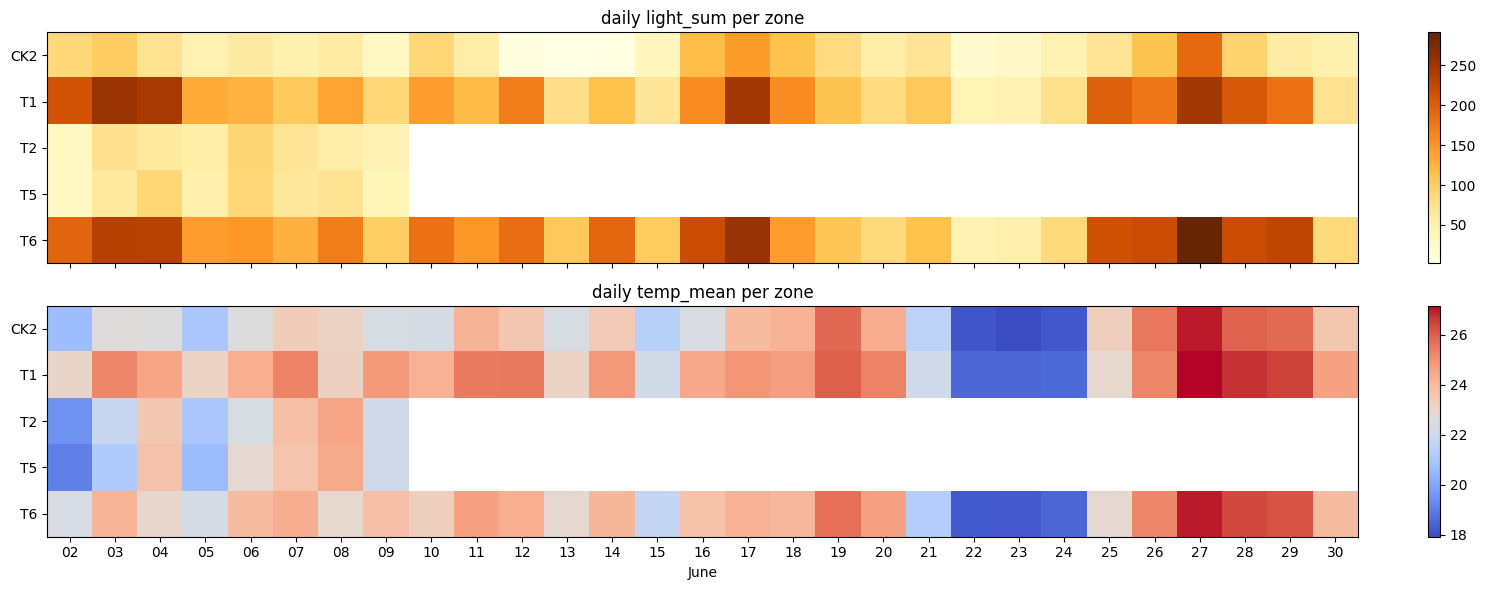

Dull (low-light) days: ['22 Jun', '23 Jun']
Zone averages over the month (descriptive):


,temp_mean,temp_max,temp_min,rh_mean,light_sum,vpd_day,co2_day
zone,,,,,,,
CK2,22.87,29.86,16.91,74.51,67.16,1.05,474.18
T1,23.98,32.23,17.47,69.54,141.42,1.41,534.44
T2,22.33,33.29,14.67,64.64,61.28,1.65,491.40
T5,22.21,33.62,14.48,64.78,62.77,1.66,534.61
T6,23.38,31.58,17.13,71.13,159.46,1.26,484.74


Note: light sums differ a lot between zones although zones share one greenhouse roof -> sensor placement/shading matters; compare light between zones with care.


In [8]:
def vpd_kpa(t, rh):
    es = 0.6108 * np.exp(17.27 * t / (t + 237.3))
    return es * (1 - rh / 100)

z = zone_ts[zone_ts.zone != 'GH_MEAN'].copy()
z['date'] = z['time'].dt.normalize()
z['is_day'] = z['light'] > 0.5
z['vpd'] = vpd_kpa(z['air_temp'], z['rh'])
daily_env = z.groupby(['zone', 'date']).agg(
    temp_mean=('air_temp', 'mean'), temp_max=('air_temp', 'max'), temp_min=('air_temp', 'min'),
    rh_mean=('rh', 'mean'), light_sum=('light', lambda v: v.sum() * 0.5),
    vpd_day=('vpd', lambda v: v[z.loc[v.index, 'is_day']].mean()),
    co2_day=('co2', lambda v: v[z.loc[v.index, 'is_day']].mean()),
    n_readings=('air_temp', 'size')).reset_index()
daily_env = daily_env[daily_env.n_readings >= 40]            # keep (almost) complete days only

fig, axes = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
for ax, v, cmap in zip(axes, ['light_sum', 'temp_mean'], ['YlOrBr', 'coolwarm']):
    h = daily_env.pivot(index='zone', columns='date', values=v)
    im = ax.imshow(h.values, aspect='auto', cmap=cmap)
    ax.set_yticks(range(len(h.index))); ax.set_yticklabels(h.index); ax.set_title(f'daily {v} per zone')
    plt.colorbar(im, ax=ax, fraction=.02)
axes[1].set_xticks(range(len(h.columns))); axes[1].set_xticklabels([d.strftime('%d') for d in h.columns])
axes[1].set_xlabel('June')
plt.tight_layout(); plt.show()

# Dull days: greenhouse daily light below half of the month's median
gh_light = daily_env.groupby('date')['light_sum'].mean()
print('Dull (low-light) days:', [d.strftime('%d %b') for d in gh_light[gh_light < .5 * gh_light.median()].index])

print('Zone averages over the month (descriptive):')
display(daily_env.groupby('zone')[['temp_mean', 'temp_max', 'temp_min', 'rh_mean', 'light_sum', 'vpd_day', 'co2_day']].mean().round(2))
print('Note: light sums differ a lot between zones although zones share one greenhouse roof ->'
      ' sensor placement/shading matters; compare light between zones with care.')

## 2. Plant measurements (the target)

- `processed_data/growth_indexfinal/2025MMDD.csv` has a row for every plant for every day 1–13 June.
- `raw_data/growth_index/` only has the days that were **really measured** (in June: 7 and 13).

So most daily values are **interpolated**. We keep a column `is_measured` so we never evaluate a model on interpolated targets by accident.

In [9]:
TRAITS = ['Plant Height', 'Stem Diameter', 'Leaf Width', 'Leaf Length', 'NDVI', 'RVI', 'LNC', 'LNA', 'LAI', 'LDW']

daily = []
for f in sorted((MONTH_DIR / 'processed_data' / 'growth_index(final)').glob('*.csv')):
    d = pd.read_csv(f)
    d['date'] = pd.to_datetime(f.stem, format='%Y%m%d')
    daily.append(d)
growth = pd.concat(daily, ignore_index=True).rename(columns={'Number': 'plant'})

raw_dates = sorted(pd.to_datetime(p.stem, format='%Y%m%d')
                   for p in (MONTH_DIR / 'raw_data' / 'growth_index').glob('*.csv'))
print('Really measured days in June:', [d.date() for d in raw_dates])
growth['is_measured'] = growth['date'].isin(raw_dates)

# Plant code -> treatment / variety / replicate  (L213 = treatment 2, variety 1, rep 3; CK12 = control, variety 1, rep 2)
def parse_plant(code):
    if code.startswith('CK'):
        return 'CK', int(code[2]), int(code[3:])
    digits = code[1:]
    return f'T{digits[0]}', int(digits[1]), int(digits[2:])
growth[['treatment', 'variety', 'rep']] = pd.DataFrame(growth['plant'].map(parse_plant).tolist(), index=growth.index)
growth['variety_name'] = growth['variety'].map({1: 'Guanghui 201', 2: 'Jinzhu (cherry)'})
growth['camera'] = growth['Photo Path'].str.split('/').str[1].str.replace(',', '', regex=False)

print(growth.shape)
display(growth[['plant', 'date', 'is_measured', 'treatment', 'variety_name', 'camera'] + TRAITS].head())
display(growth[TRAITS].isna().sum().rename('missing'))

Really measured days in June: [datetime.date(2025, 6, 7), datetime.date(2025, 6, 13)]
(780, 21)


,plant,date,is_measured,treatment,variety_name,camera,Plant Height,Stem Diameter,Leaf Width,Leaf Length,NDVI,RVI,LNC,LNA,LAI,LDW
0,L111,2025-06-01,False,T1,Guanghui 201,111211,196.0,12.9,44.0,44.0,0.41,2.46,2.14,0.13,1.47,0.07
1,L112,2025-06-01,False,T1,Guanghui 201,111211,206.0,10.6,16.0,33.0,0.45,2.42,2.23,0.16,1.56,0.07
2,L113,2025-06-01,False,T1,Guanghui 201,111211,194.0,13.5,34.0,36.0,0.49,2.53,2.37,0.20,1.72,0.07
3,L121,2025-06-01,False,T1,Jinzhu (cherry),111211,216.0,12.3,18.0,38.0,0.43,2.35,2.20,0.15,1.62,0.07
4,L122,2025-06-01,False,T1,Jinzhu (cherry),111211,188.0,14.3,35.0,49.0,0.48,2.72,2.67,0.24,1.96,0.08


,missing
Plant Height,0
Stem Diameter,0
Leaf Width,0
Leaf Length,0
NDVI,0
RVI,0
LNC,0
LNA,0
LAI,0
LDW,0


In [10]:
# Sanity check: processed values on measured days == raw file values
col_map = {'编号': 'plant', '株高': 'Plant Height', '茎粗': 'Stem Diameter', '叶宽-1': 'Leaf Width', '叶长-1': 'Leaf Length'}
for d in raw_dates:
    raw = pd.read_csv(MONTH_DIR / 'raw_data' / 'growth_index' / f'{d:%Y%m%d}.csv', encoding='gbk').rename(columns=col_map)
    m = growth[growth.date == d].merge(raw, on='plant', suffixes=('', '_raw'))
    diff = (m['Plant Height'] - m['Plant Height_raw']).abs().max()
    print(f'{d.date()}: {len(raw)} rows in raw file, {len(m)} matched, max |height diff| = {diff}')
    print('   plants only in raw file:', sorted(set(raw.plant) - set(growth.plant))[:12], '...')

2025-06-07: 108 rows in raw file, 60 matched, max |height diff| = 0.0
   plants only in raw file: ['CK14', 'CK15', 'CK16', 'CK24', 'CK25', 'CK26', 'R114', 'R115', 'R116', 'R124', 'R125', 'R126'] ...
2025-06-13: 108 rows in raw file, 60 matched, max |height diff| = 0.0
   plants only in raw file: ['CK14', 'CK15', 'CK16', 'CK24', 'CK25', 'CK26', 'R114', 'R115', 'R116', 'R124', 'R125', 'R126'] ...


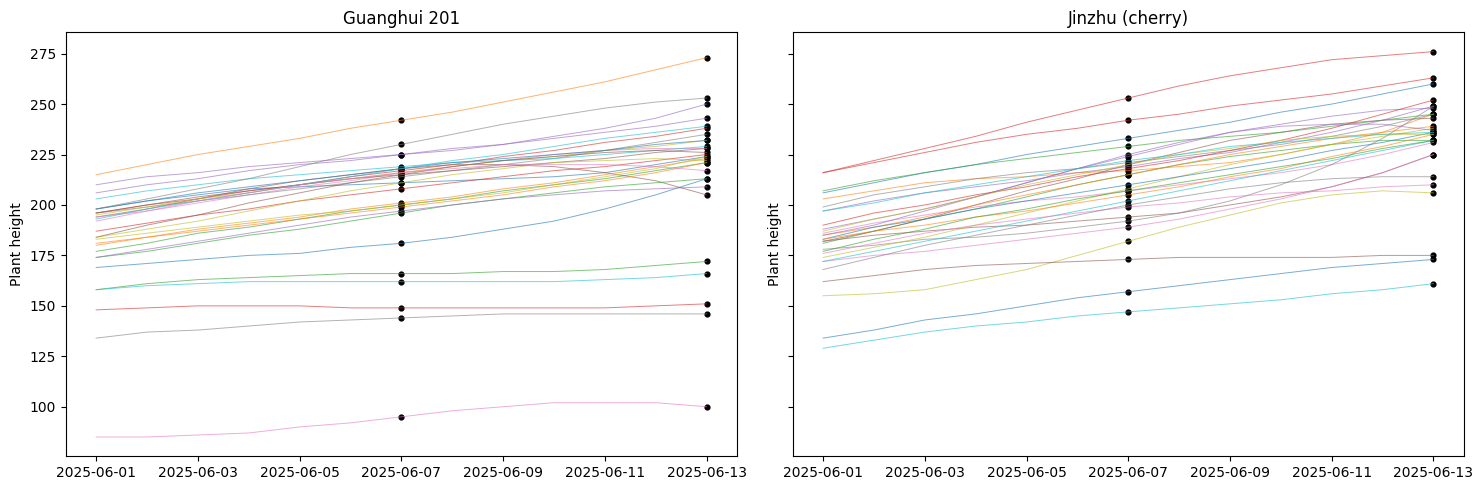

,plant,date,Plant Height,dH,treatment,variety_name
722,L113,2025-06-13,205.0,-13.0,T1,Guanghui 201


In [11]:
# Height trajectories: dots = really measured, lines = interpolated
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (var, g) in zip(axes, growth.groupby('variety_name')):
    for plant, p in g.groupby('plant'):
        ax.plot(p['date'], p['Plant Height'], lw=.7, alpha=.6)
        ax.scatter(p.loc[p.is_measured, 'date'], p.loc[p.is_measured, 'Plant Height'], s=12, color='k')
    ax.set_title(var); ax.set_ylabel('Plant height')
plt.tight_layout(); plt.show()

# Plants whose height goes DOWN between measured days (pruning? measurement error?) -> error-analysis candidates
meas = growth[growth.is_measured].sort_values('date')
meas['dH'] = meas.groupby('plant')['Plant Height'].diff()
display(meas[meas.dH < 0][['plant', 'date', 'Plant Height', 'dH', 'treatment', 'variety_name']])

In [12]:
# Treatment / variety differences (descriptive only, no causal claims)
first, last = growth.date.min(), growth.date.max()
g2 = growth[growth.date.isin([first, last])].pivot_table(index=['plant', 'treatment', 'variety_name'],
                                                          columns='date', values='Plant Height')
g2.columns = ['h_first', 'h_last']
g2['growth'] = g2['h_last'] - g2['h_first']
display(g2.groupby(['variety_name', 'treatment'])['growth'].agg(['mean', 'std', 'count']).round(1))
growth.to_parquet(OUT_DIR / 'growth_daily.parquet', index=False)

mean   std  count
variety_name    treatment                   
Guanghui 201    CK         42.7  16.0      3
                T1         30.0  16.6      3
                T2         35.0   5.1      6
                T3         39.0   1.0      3
                T4         34.0  20.1      3
                T5         31.3  18.2      6
                T6         27.2  14.7      6
Jinzhu (cherry) CK         49.0   6.2      3
                T1         56.0   7.8      3
                T2         44.5   8.0      6
                T3         50.0  11.1      3
                T4         55.7  14.2      3
                T5         57.7   5.0      6
                T6         38.7  14.1      6

## 2b. All plants measured by hand (raw files)

The raw measurement files contain **108 plants**, not only the 60 in the processed files: the extra ones are
`R…` plants (the other row) and extra controls (`CK14…CK26`). They were photographed by **other cameras that are not in this
dataset**, so they cannot be used for the image model — but they can be used to check whether the numerical model's results
hold with a bigger sample (sensitivity check in notebook 02).

In [13]:
RAW_COLS = {'相机': 'camera_label_cn', '编号': 'plant', '株高': 'Plant Height', '茎粗': 'Stem Diameter',
            '叶宽-1': 'Leaf Width', '叶长-1': 'Leaf Length'}

def parse_any_plant(code):
    """L213 / R2110 / CK14 -> (side, treatment, variety, rep)"""
    if code.startswith('CK'):
        return 'CK', 'CK', int(code[2]), int(code[3:])
    side, d = code[0], code[1:]
    return side, f'T{d[0]}', int(d[1]), int(d[2:])

def camera_label_en(lbl):
    lbl = lbl.replace('（', '(').replace('）', ')').replace(' ', '')
    lbl = lbl.replace('处理', 'T').replace('对照', 'CK').replace('、', '+')
    return lbl.replace('前', ' front').replace('中', ' middle').replace('后', ' back')

raw_all = []
for p in sorted((MONTH_DIR / 'raw_data' / 'growth_index').glob('*.csv')):
    d = pd.read_csv(p, encoding='gbk').rename(columns=RAW_COLS)
    d['date'] = pd.to_datetime(p.stem, format='%Y%m%d')
    raw_all.append(d)
raw_all = pd.concat(raw_all, ignore_index=True)
raw_all[['side', 'treatment', 'variety', 'rep']] = pd.DataFrame(raw_all['plant'].map(parse_any_plant).tolist(),
                                                                 index=raw_all.index)
raw_all['variety_name'] = raw_all['variety'].map({1: 'Guanghui 201', 2: 'Jinzhu (cherry)'})
raw_all['camera_label'] = raw_all['camera_label_cn'].map(camera_label_en)
raw_all['in_image_set'] = raw_all['plant'].isin(growth['plant'])

print(raw_all.groupby('date').plant.nunique().rename('plants per measured day'))
display(raw_all.drop_duplicates('plant').groupby(['camera_label', 'in_image_set']).plant.apply(list))
raw_all.to_parquet(OUT_DIR / 'growth_measured_all.parquet', index=False)

date
2025-06-07    108
2025-06-13    108
Name: plants per measured day, dtype: int64


camera_label    in_image_set
(CK2T4) middle  True            [CK11, CK12, CK13, CK21, CK22, CK23, L411, L41...
(T1+2) back     False           [R114, R115, R124, R125, R126, R217, R218, R21...
(T1+2) front    True            [L111, L112, L113, L121, L122, L123, L214, L21...
(T1+3) back     False                                                      [R116]
(T2+3) middle   False           [R2110, R2111, R2112, R2210, R2211, R2212, R31...
                True            [L211, L212, L213, L221, L222, L223, L311, L31...
(T4+CK2) front  False           [CK14, CK15, CK16, CK24, CK25, CK26, R414, R41...
(T5+6) back     True            [L511, L512, L513, L521, L522, L523, L611, L61...
(T5+6) middle   False           [R517, R518, R519, R527, R528, R529, R617, R61...
                True            [L514, L515, L516, L524, L525, L526, L614, L61...
Name: plant, dtype: object

## 2c. Plant measurements: distributions, outliers, changes (real measurements only)

Only the two real measurement days are used here (108 plants from the raw files), so interpolated values cannot
create fake patterns. Units are not documented; height is most likely cm and stem diameter mm.

Missing values per trait (raw files):


,Plant Height,Stem Diameter,Leaf Width,Leaf Length,NDVI,RVI,LNC,LNA,LAI,LDW
missing,0,0,0,0,0,0,0,0,0,0


07 Jun                        13 Jun                       
                 mean    std    min     max    mean    std     min     max
Plant Height   203.28  23.20  95.00  253.00  221.05  26.79  100.00  276.00
Stem Diameter   13.43   1.84   8.00   17.00   13.54   1.92    7.70   19.10
Leaf Width      31.91   7.98  10.00   49.00   31.65   7.99   10.00   55.00
Leaf Length     40.64   7.09  23.00   60.00   41.64   6.86   26.00   61.00
NDVI             0.44   0.02   0.39    0.52    0.44   0.02    0.37    0.50
RVI              2.57   0.14   2.30    3.10    2.53   0.17    1.51    2.89
LNC              2.38   0.13   2.06    2.72    2.35   0.11    2.08    2.57
LNA              0.17   0.02   0.13    0.22    0.17   0.02    0.13    0.21
LAI              1.64   0.09   1.42    1.94    1.62   0.08    1.43    1.82
LDW              0.07   0.00   0.06    0.08    0.07   0.00    0.06    0.08

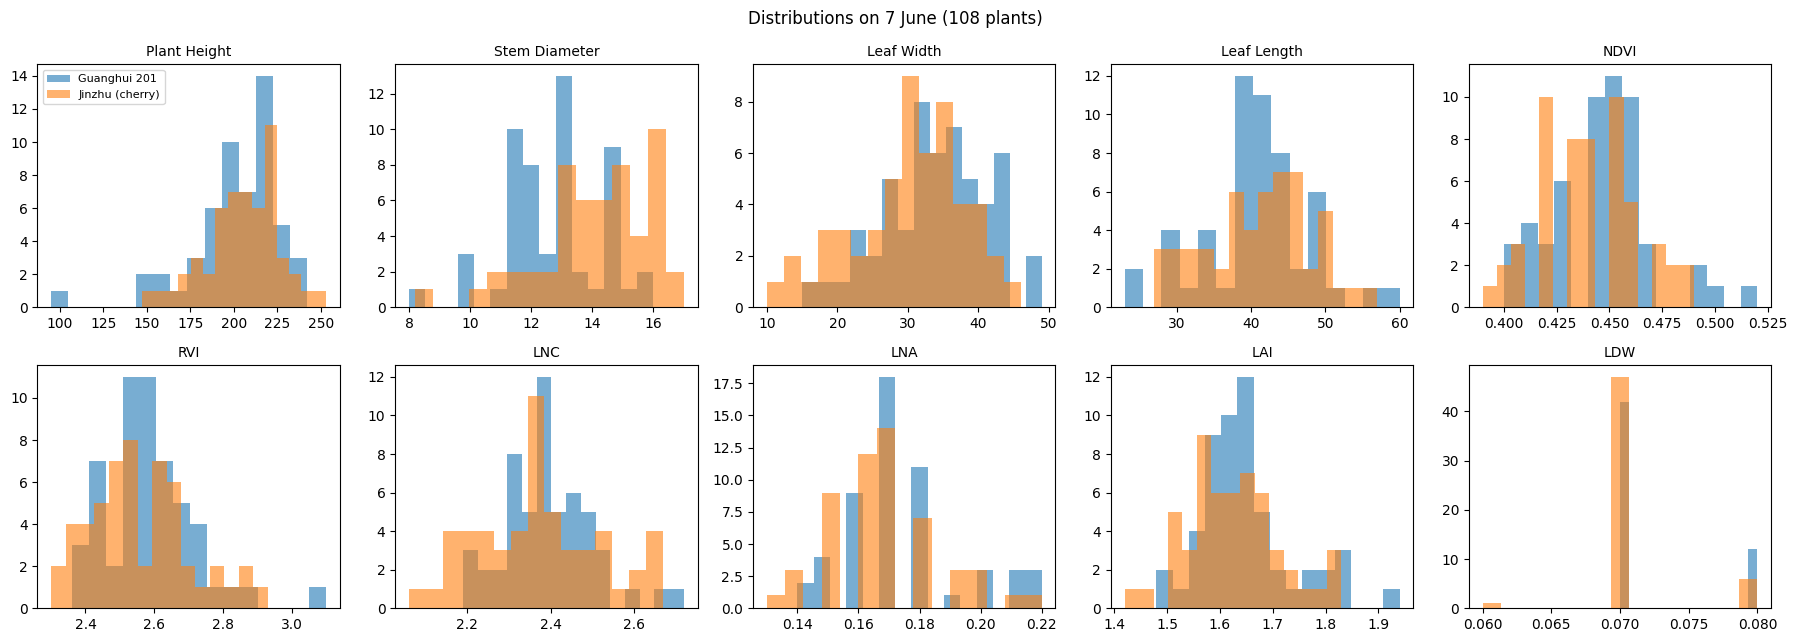

In [14]:
TRAITS_ALL = ['Plant Height', 'Stem Diameter', 'Leaf Width', 'Leaf Length', 'NDVI', 'RVI', 'LNC', 'LNA', 'LAI', 'LDW']
print('Missing values per trait (raw files):')
display(raw_all[TRAITS_ALL].isna().sum().rename('missing').to_frame().T)
stats = raw_all.groupby('date')[TRAITS_ALL].agg(['mean', 'std', 'min', 'max']).T
stats.columns = [f'{d:%d %b}' for d in stats.columns]
display(stats.unstack(1).round(2))

# Distributions on 7 June by variety
fig, axes = plt.subplots(2, 5, figsize=(18, 6.5))
t0_all = raw_all[raw_all.date == raw_all.date.min()]
for ax, tr in zip(axes.ravel(), TRAITS_ALL):
    for v, g in t0_all.groupby('variety_name'):
        ax.hist(g[tr], bins=15, alpha=.6, label=v)
    ax.set_title(tr, fontsize=10)
axes[0, 0].legend(fontsize=8)
plt.suptitle('Distributions on 7 June (108 plants)'); plt.tight_layout(); plt.show()

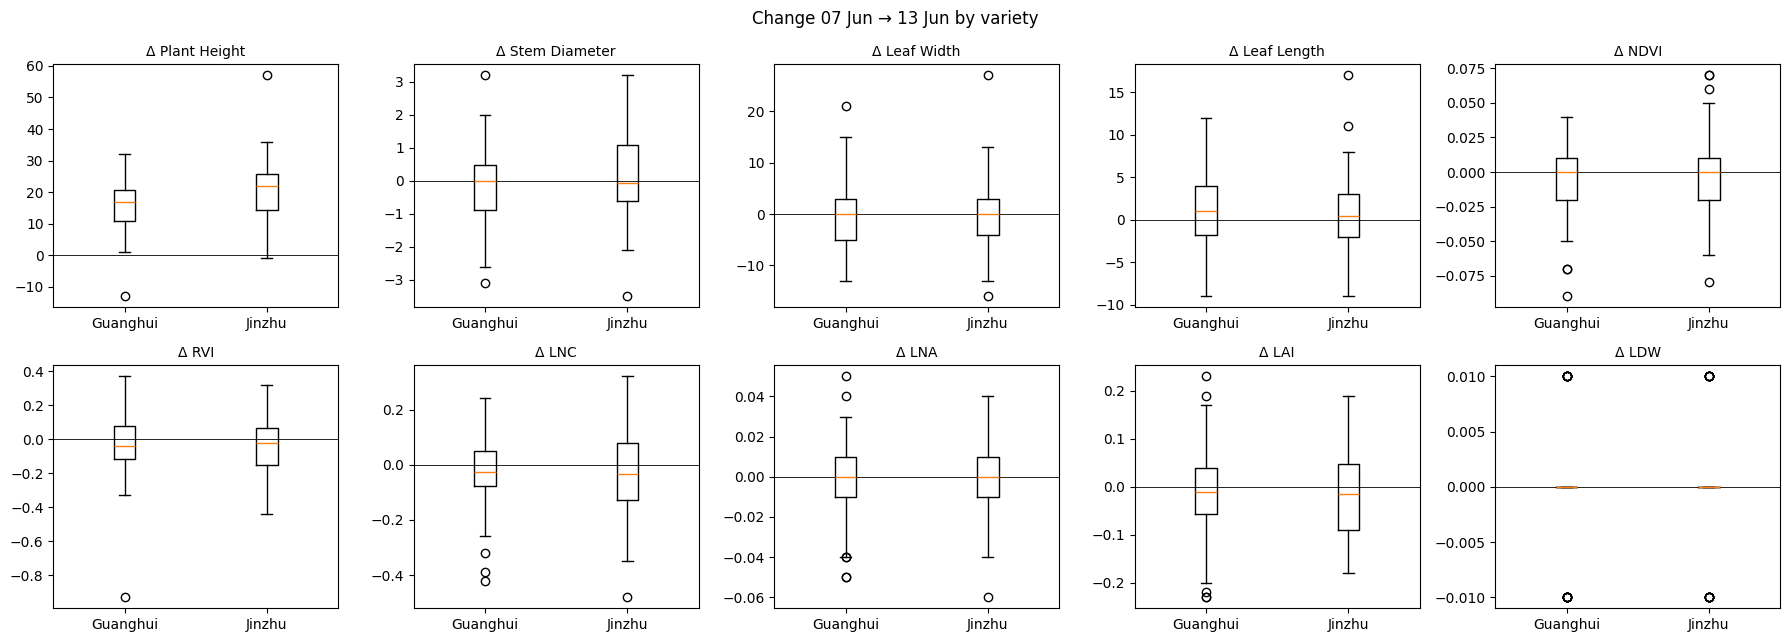

7 outlying changes (|robust z| > 3.5):


,plant,trait,value,robust_z,in_image_set
5,L512,Δ RVI,-0.93,-6.07,True
1,L423,Δ Plant Height,57.00,4.78,True
3,R124,Δ Leaf Width,27.00,4.55,False
6,CK21,Δ LNA,-0.06,-4.05,True
0,L113,Δ Plant Height,-13.00,-3.80,True
4,R124,Δ Leaf Length,17.00,3.60,False
2,L615,Δ Leaf Width,21.00,3.54,True


Negative height changes (biologically implausible as growth -> pruning, broken stem or measurement error):


,plant,variety_name,treatment,Plant Height
10,CK25,Jinzhu (cherry),CK,-1.0
14,L113,Guanghui 201,T1,-13.0
88,R325,Jinzhu (cherry),T3,-1.0


In [15]:
# Change between the two measured days, per trait
wide = raw_all.pivot_table(index=['plant', 'variety_name', 'treatment', 'in_image_set'], columns='date', values=TRAITS_ALL)
d0, d1 = sorted(raw_all.date.unique())
change = pd.DataFrame({tr: wide[(tr, d1)] - wide[(tr, d0)] for tr in TRAITS_ALL}).reset_index()

fig, axes = plt.subplots(2, 5, figsize=(18, 6.5))
for ax, tr in zip(axes.ravel(), TRAITS_ALL):
    data_v = [g[tr].dropna() for _, g in change.groupby('variety_name')]
    ax.boxplot(data_v); ax.set_xticks([1, 2]); ax.set_xticklabels(['Guanghui', 'Jinzhu'])
    ax.axhline(0, color='k', lw=.6); ax.set_title(f'Δ {tr}', fontsize=10)
plt.suptitle(f'Change {pd.Timestamp(d0):%d %b} → {pd.Timestamp(d1):%d %b} by variety'); plt.tight_layout(); plt.show()

# Systematic outlier check: robust z-score (median / MAD) on the change of each trait
def robust_z(x):
    dev = np.abs(x - np.median(x))
    mad = np.median(dev)
    if mad == 0:                      # coarse traits (e.g. LDW in steps of 0.01): fall back to mean absolute deviation
        mad = 0.7979 * dev.mean()
    return 0.6745 * (x - np.median(x)) / mad if mad > 0 else np.zeros_like(x)
flags = []
for tr in TRAITS_ALL:
    if change[tr].nunique() <= 3:
        print(f'Δ {tr}: only {change[tr].nunique()} distinct values (measurement resolution too coarse) -> skipped')
        continue
    rz = robust_z(change[tr].values)
    for i in np.where(np.abs(rz) > 3.5)[0]:
        flags.append({'plant': change.plant[i], 'trait': f'Δ {tr}', 'value': change[tr][i], 'robust_z': rz[i],
                      'in_image_set': change.in_image_set[i]})
outliers = pd.DataFrame(flags).sort_values('robust_z', key=np.abs, ascending=False)
print(f'{len(outliers)} outlying changes (|robust z| > 3.5):')
display(outliers.round(2).head(20))
print('Negative height changes (biologically implausible as growth -> pruning, broken stem or measurement error):')
display(change[change['Plant Height'] < 0][['plant', 'variety_name', 'treatment', 'Plant Height']])

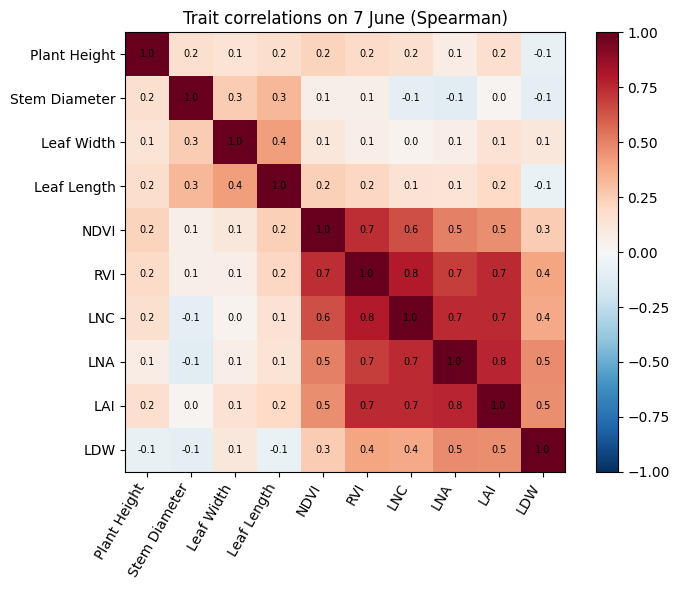

Median height gain by variety × treatment (all 108 plants; n per cell is small -> descriptive only):


median                        count                
variety_name Guanghui 201 Jinzhu (cherry) Guanghui 201 Jinzhu (cherry)
treatment                                                             
CK                   19.0            22.0            6               6
T1                   17.0            22.0            6               6
T2                   17.5            23.5           12              12
T3                   16.0            19.5            6               6
T4                   12.5            25.5            6               6
T5                   19.0            26.0            9               9
T6                   11.0            14.0            9               9

In [16]:
# How do the traits relate to each other? (Spearman, 7 June) -> redundancy between features
c = t0_all[TRAITS_ALL].corr(method='spearman')
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(c.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(c))); ax.set_xticklabels(c.columns, rotation=60, ha='right'); ax.set_yticks(range(len(c))); ax.set_yticklabels(c.index)
for i in range(len(c)):
    for j in range(len(c)):
        ax.text(j, i, f'{c.values[i, j]:.1f}', ha='center', va='center', fontsize=7)
plt.colorbar(im, fraction=.04); ax.set_title('Trait correlations on 7 June (Spearman)')
plt.tight_layout(); plt.show()

print('Median height gain by variety × treatment (all 108 plants; n per cell is small -> descriptive only):')
display(change.pivot_table(index='treatment', columns='variety_name', values='Plant Height', aggfunc=['median', 'count']))

**What to note here:** handheld indices (NDVI, RVI, LNC, LNA, LAI, LDW) vary little between plants and
between days compared with height; several are strongly correlated with each other (they come from the same
sensor), so they carry overlapping information. Height gain differs clearly between varieties.

## 3. Images

File name = `<upload_time>_<capture_time>_<camera_id>.jpg` (unix seconds). We use the **capture** time, converted to
greenhouse local time (UTC+8). Each camera looks down on ~12 plants, so an image describes a **group of plants**, not one plant.

In [17]:
img_rows = []
for p in (MONTH_DIR / 'images').rglob('*.jpg'):
    up, cap, cam_id = p.stem.split('_')
    img_rows.append({'path': str(p.relative_to(MONTH_DIR)),
                     'camera': p.parent.name.replace(',', ''),
                     'camera_id': int(cam_id),
                     'capture_utc': pd.to_datetime(int(cap), unit='s')})
images = pd.DataFrame(img_rows)
images['capture_local'] = images['capture_utc'] + pd.Timedelta(hours=LOCAL_TZ_OFFSET_H)
images['date'] = images['capture_local'].dt.normalize()
images['hour'] = images['capture_local'].dt.hour
images = images.sort_values(['camera', 'capture_local']).reset_index(drop=True)

print(len(images), 'images')
display(images.groupby('camera').agg(n=('path', 'size'), first=('capture_local', 'min'), last=('capture_local', 'max')))
display(images.pivot_table(index='date', columns='camera', values='path', aggfunc='size').head(15))
print('Capture hours:', images['hour'].value_counts().sort_index().to_dict())
images.to_parquet(OUT_DIR / 'image_index.parquet', index=False)

745 images


,n,first,last
camera,,,
111211,145,2025-06-01 08:11:04,2025-06-30 18:11:04
11411,150,2025-06-01 08:12:22,2025-06-30 18:12:18
214311,150,2025-06-01 08:11:43,2025-06-30 18:11:47
511611,150,2025-06-01 08:11:04,2025-06-30 18:11:03
514614,150,2025-06-01 08:11:43,2025-06-30 18:11:45


camera,111211,11411,214311,511611,514614
date,,,,,
2025-06-01,3,5,5,5,5
2025-06-02,5,5,5,5,6
2025-06-03,5,5,5,5,5
2025-06-04,6,6,5,5,5
2025-06-05,5,5,5,5,5
2025-06-06,5,5,5,5,5
2025-06-07,5,5,5,5,5
2025-06-08,5,5,5,5,5
2025-06-09,5,5,5,5,5


Capture hours: {8: 151, 10: 148, 14: 147, 16: 149, 18: 150}


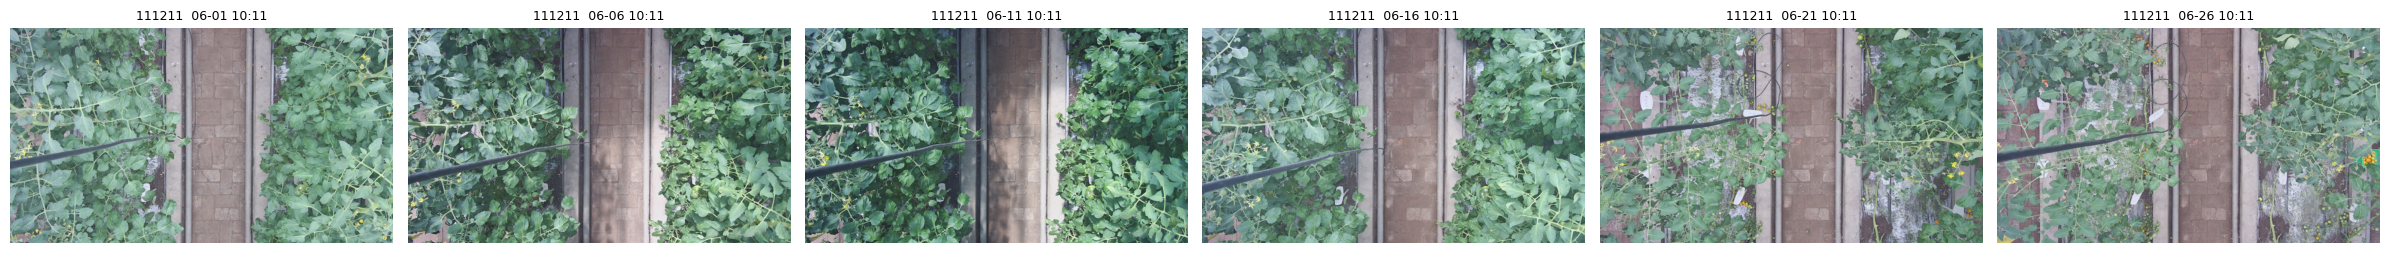

In [18]:
# Look at a few images from one camera over time (lighting, occlusion, canopy closing)
from PIL import Image
cam = images['camera'].iloc[0]
sample = images[(images.camera == cam) & images.hour.between(10, 14)].groupby('date').head(1).iloc[::5]
fig, axes = plt.subplots(1, len(sample), figsize=(4 * len(sample), 3))
for ax, (_, r) in zip(np.atleast_1d(axes), sample.iterrows()):
    im = Image.open(MONTH_DIR / r.path); im.thumbnail((640, 640))
    ax.imshow(im); ax.set_title(f'{cam}  {r.capture_local:%m-%d %H:%M}', fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

## 3b. Image data: quality, lighting, canopy, occlusion (all images)

Every image is opened at low resolution (JPEG draft mode, fast) and described by a few numbers:
- **brightness / contrast** → lighting conditions
- **sharpness** (variance of the Laplacian; low = blurred / foggy lens)
- **over-exposed / dark pixel share** → glare and shadows
- **green-canopy fraction** (excess-green index) → how much of the scene is leaf, i.e. canopy size/closure
Results are cached on Drive (`image_quality.parquet`).

In [19]:
QC_CACHE = OUT_DIR / 'image_quality.parquet'

def image_stats(path):
    im = Image.open(MONTH_DIR / path); im.draft('RGB', (480, 270)); im = im.convert('RGB')
    im.thumbnail((480, 270))
    a = np.asarray(im).astype(np.float32) / 255
    r, g, b = a[..., 0], a[..., 1], a[..., 2]
    gray = a.mean(-1)
    lap = gray[:-2, 1:-1] + gray[2:, 1:-1] + gray[1:-1, :-2] + gray[1:-1, 2:] - 4 * gray[1:-1, 1:-1]
    exg = (2 * g - r - b) / (r + g + b + 1e-6)
    return {'brightness': gray.mean(), 'contrast': gray.std(), 'sharpness': lap.var() * 1e3,
            'overexposed': (a.max(-1) > .95).mean(), 'dark': (gray < .08).mean(), 'green_frac': (exg > .10).mean()}

if QC_CACHE.exists():
    qc = pd.read_parquet(QC_CACHE)
else:
    rows = []
    for i, r in enumerate(images.itertuples()):
        rows.append({'path': r.path, **image_stats(r.path)})
        if i % 50 == 0:
            print(f'{i}/{len(images)}', end='\r')
    qc = pd.DataFrame(rows); qc.to_parquet(QC_CACHE, index=False)
qc = images.merge(qc, on='path')
display(qc[['brightness', 'contrast', 'sharpness', 'overexposed', 'dark', 'green_frac']].describe().round(3))

,brightness,contrast,sharpness,overexposed,dark,green_frac
count,745.000,745.000,745.000,745.000,745.0,745.000
mean,0.523,0.131,35.553,0.001,0.0,0.371
std,0.035,0.022,8.488,0.001,0.0,0.130
min,0.408,0.081,15.669,0.000,0.0,0.005
25%,0.504,0.116,29.986,0.000,0.0,0.289
50%,0.536,0.124,34.089,0.001,0.0,0.369
75%,0.546,0.145,41.099,0.001,0.0,0.461
max,0.577,0.189,66.411,0.007,0.0,0.668


Camera-days with fewer than 5 images:


camera,111211,11411,214311,511611,514614
2025-06-01,3,5,5,5,5
2025-06-10,4,4,5,5,4
2025-06-13,4,5,5,5,5
2025-06-21,4,5,5,5,5
2025-06-22,4,5,5,5,5


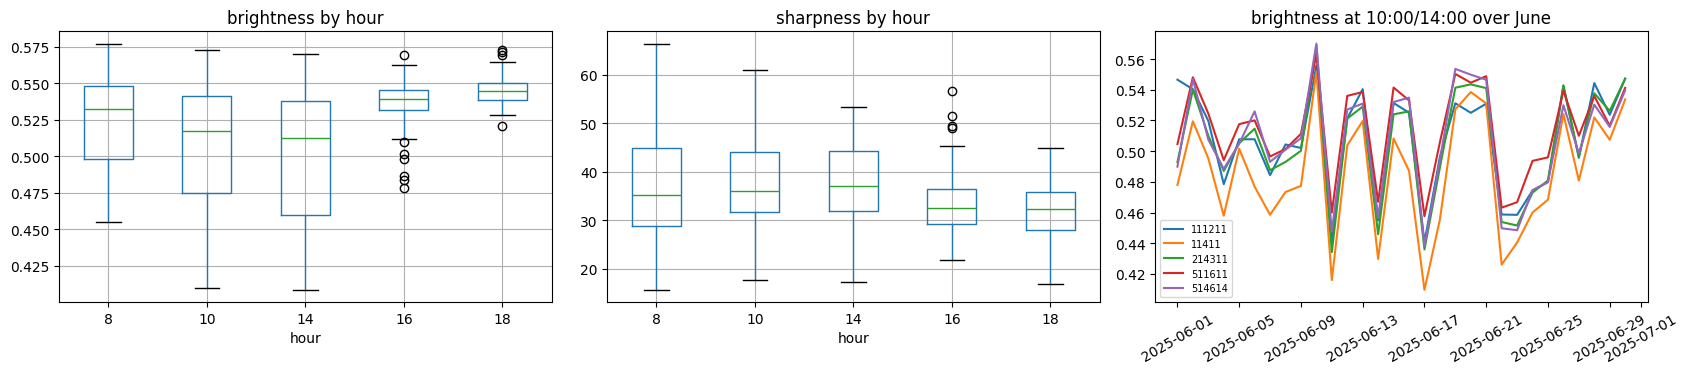

In [20]:
# Missing images: expected 5 per camera per day (08, 10, 14, 16, 18 h)
cnt = qc.pivot_table(index='date', columns='camera', values='path', aggfunc='size').reindex(
    pd.date_range(qc.date.min(), qc.date.max(), freq='D')).fillna(0).astype(int)
print('Camera-days with fewer than 5 images:')
display(cnt[(cnt < 5).any(axis=1)])

# Lighting by hour of day, and over the month
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
qc.boxplot(column='brightness', by='hour', ax=axes[0]); axes[0].set_title('brightness by hour')
qc.boxplot(column='sharpness', by='hour', ax=axes[1]); axes[1].set_title('sharpness by hour')
for cam, g in qc[qc.hour.isin([10, 14])].groupby('camera'):
    d = g.groupby('date')['brightness'].mean(); axes[2].plot(d.index, d.values, label=cam)
axes[2].set_title('brightness at 10:00/14:00 over June'); axes[2].legend(fontsize=7); axes[2].tick_params(axis='x', rotation=30)
plt.suptitle(''); plt.tight_layout(); plt.show()

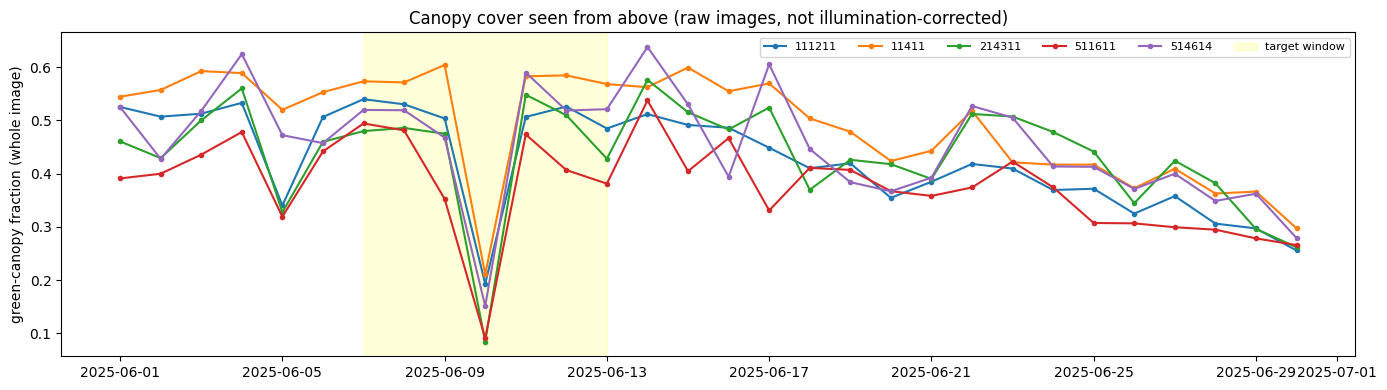

Correlation between daily brightness and green fraction (same images): -0.5 -> colour-based canopy measures partly follow the lighting; notebook 03 corrects this with the walkway.


In [21]:
# Canopy over the month: green fraction per camera (10:00 and 14:00 images, daily mean)
fig, ax = plt.subplots(figsize=(14, 4))
for cam, g in qc[qc.hour.isin([10, 14])].groupby('camera'):
    d = g.groupby('date')['green_frac'].mean(); ax.plot(d.index, d.values, marker='o', ms=3, label=cam)
ax.axvspan(pd.Timestamp('2025-06-07'), pd.Timestamp('2025-06-13'), color='yellow', alpha=.15, label='target window')
ax.set_ylabel('green-canopy fraction (whole image)'); ax.legend(ncol=6, fontsize=8)
ax.set_title('Canopy cover seen from above (raw images, not illumination-corrected)')
plt.tight_layout(); plt.show()
print('Correlation between daily brightness and green fraction (same images):',
      round(qc[qc.hour.isin([10, 14])][['brightness', 'green_frac']].corr().iloc[0, 1], 2),
      '-> colour-based canopy measures partly follow the lighting; notebook 03 corrects this with the walkway.')

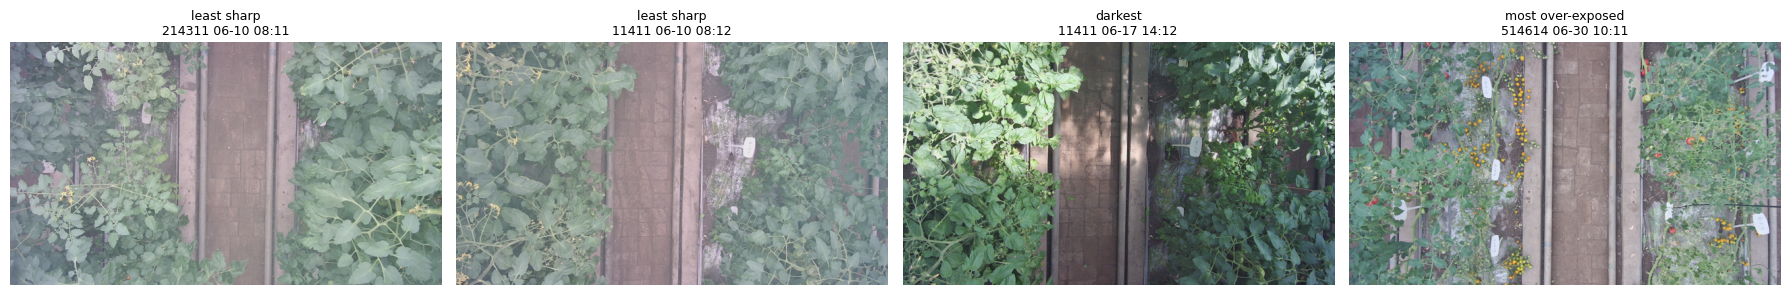

In [22]:
# Worst images: the least sharp, darkest and most over-exposed
worst = pd.concat([qc.nsmallest(2, 'sharpness').assign(issue='least sharp'),
                   qc.nsmallest(1, 'brightness').assign(issue='darkest'),
                   qc.nlargest(1, 'overexposed').assign(issue='most over-exposed')])
fig, axes = plt.subplots(1, len(worst), figsize=(4.5 * len(worst), 3))
for ax, (_, r) in zip(axes, worst.iterrows()):
    im = Image.open(MONTH_DIR / r.path); im.draft('RGB', (640, 360)); im = im.convert('RGB'); im.thumbnail((640, 360))
    ax.imshow(im); ax.set_title(f'{r.issue}\n{r.camera} {r.capture_local:%m-%d %H:%M}', fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

**Image observations to write down:**
- *Viewpoint:* all cameras look straight down → leaf area and flowers are visible, **plant height is not**.
- *Canopy:* by June the canopy is closed; leaves of neighbouring plants overlap → individual plants are hard to separate (occlusion).
- *Fixed occluders:* irrigation hose, plant labels, walkway and bed edges appear in every image of a camera.
- *Lighting:* strong effect of hour (shadows morning/evening, glare midday) and of weather (haze on some days) → use fixed hours (10:00/14:00) and correct colour (notebook 03).
- *Canopy over time:* look for drops in green fraction that are not explained by brightness — e.g. leaf removal (de-leafing) late in June.
- *Missing images:* a few camera-days have fewer than 5 images (see table).

## 4. Plant → camera → sensor zone map

- Camera: taken from the `Photo Path` column of the growth CSVs.
- Sensor zone: a plant's treatment number (T1, T2, T5, T6, CK→CK2). **T3 and T4 have no sensor**, so they get the greenhouse mean and a flag `zone_is_proxy=True`. This is an assumption to state in the README.

In [23]:
zones_with_sensor = set(zone_ts['zone']) - {'GH_MEAN'}
plants = growth[['plant', 'treatment', 'variety', 'variety_name', 'rep', 'camera']].drop_duplicates('plant')
plants['sensor_zone'] = plants['treatment'].map(lambda t: 'CK2' if t == 'CK' else t)
plants['zone_is_proxy'] = ~plants['sensor_zone'].isin(zones_with_sensor)
plants.loc[plants.zone_is_proxy, 'sensor_zone'] = 'GH_MEAN'
plants.to_csv(OUT_DIR / 'plant_map.csv', index=False)
display(plants.groupby(['camera', 'sensor_zone', 'zone_is_proxy']).plant.apply(list))
print('Saved to', OUT_DIR, ':', sorted(p.name for p in OUT_DIR.iterdir()))

camera  sensor_zone  zone_is_proxy
111211  T1           False            [L111, L112, L113, L121, L122, L123]
        T2           False            [L211, L212, L213, L221, L222, L223]
11411   CK2          False            [CK11, CK12, CK13, CK21, CK22, CK23]
        GH_MEAN      True             [L411, L412, L413, L421, L422, L423]
214311  GH_MEAN      True             [L311, L312, L313, L321, L322, L323]
        T2           False            [L214, L215, L216, L224, L225, L226]
511611  T5           False            [L511, L512, L513, L521, L522, L523]
        T6           False            [L611, L612, L613, L621, L622, L623]
514614  T5           False            [L514, L515, L516, L524, L525, L526]
        T6           False            [L614, L615, L616, L624, L625, L626]
Name: plant, dtype: object

Saved to /content/drive/MyDrive/alprotein_outputs : ['bootstrap_comparison.csv', 'cell_mapping_validation.csv', 'figures', 'growth_daily.parquet', 'growth_measured_all.parquet', 'image_features_plant.parquet', 'image_index.parquet', 'image_quality.parquet', 'image_region_embeddings.npy', 'image_region_embeddings_v2.npy', 'image_region_features.parquet', 'image_region_features_v2.parquet', 'image_regions.parquet', 'model_table_numerical.parquet', 'oof_image_leave_camera_out.parquet', 'plant_map.csv', 'predictions_per_plant.csv', 'results_final.csv', 'results_image.csv', 'results_numerical.csv', 'results_numerical_108.csv', 'sensors_long.parquet', 'sensors_zone_30min.parquet', 'target_window.json']


## 5. Assumptions (stated before modelling)

**Data and target**
1. Only 7 June and 13 June are real hand measurements; all other daily values in `growth_index(final)` are interpolated and are **never used as targets**.
2. Target = plant-height gain between 7 and 13 June. Measurements are assumed to be taken in the morning, so the sensor window is [7 June 00:00, 13 June 00:00).
3. Plant code = row (L/R) + treatment + variety + replicate (from the dataset README). The meaning of L/R (left/right row) is not documented.
4. Units are not documented: height most likely cm, stem diameter mm, light in an unknown unit (used only relatively).

**Sensors**
5. A plant experiences the climate measured in its treatment zone (`处理N` → TN, `对照2` → CK2). Zones without a sensor (T3, T4; T2 and T5 after 10 June) get the greenhouse mean, flagged with `zone_is_proxy`.
6. Readings of exactly 0 for temperature, RH or CO₂ are device drop-outs, not real values.
7. Soil-moisture/temperature probes are not calibrated against each other → only changes relative to each probe's own baseline are compared.

**Images**
8. Image file names contain the capture time as Unix time (UTC); local time = UTC + 8 h.
9. Camera folder `A,B` shows bed A (left) and bed B (right); inside a bed the left column is variety 1, the right column variety 2, rows top→bottom are replicates (Plant Orientation Diagram). This mapping is **tested** in notebook 03.
10. A top-down RGB camera can see canopy cover, flowers and fruit, but not stem height directly.

**Analysis**
11. Plants are treated as independent units, but plants under the same camera/zone share conditions → models are validated with leave-one-camera-out CV, not only random splits.
12. Treatment and zone are confounded with position in the greenhouse and each group has 3–6 plants → differences between treatments are **described, not interpreted causally**.

## Next (notebook 02)
- Target: **height gain 7 → 13 June** (60 plants with images; 108 in `growth_measured_all.parquet` for a numerical-only sensitivity check).
- Sensor features over the interval, phenotype on 7 June; grouped cross-validation.